In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.model_selection import KFold
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
import random
import math

In [2]:
# In this hw, the target variable "Rings" is used in two different ways.
# First, I used as a numeric value to represent the exact age of abalone it causes a lot of dimensions on confusion matrix and less accuracy.
# After that, I transformed into a categorical variable by grouping the values young-adult-old.

In [26]:
# 1. Load Data and Analyze
data = pd.read_csv('abalone.csv')
# column isimlerini kendime göre ayarladım
data.columns = ['Sex', 'Length', 'Diameter', 'Height', 'WholeWeight', 'ShuckedWeight', 'VisceraWeight', 'ShellWeight', 'Rings']

print(data.head())

print(data.info())

print(data.describe())

# numerik verilerin genel infoları
numInfos = ['Length', 'Diameter', 'Height', 'WholeWeight', 'ShuckedWeight', 'VisceraWeight', 'ShellWeight', 'Rings']

print("\nNumerik Verilerin Matematiksel Verileri:")
for feature in numInfos:
    mean_val = data[feature].mean()
    std_val = data[feature].std()
    min_val = data[feature].min()
    max_val = data[feature].max()

    print(f"{feature}: Mean = {mean_val:.4f}, Std = {std_val:.4f}, Min = {min_val:.4f}, Max = {max_val:.4f}")

# character or non numeric data to numreic data
genderMap = {'M': 0, 'F': 1, 'I': 2}
data['Sex'] = data['Sex'].map(genderMap)

attrTypes = [2] + [1] * 7  # attrTypes 1: numeric, 2: categorical

# Split features and labels
X = data.drop('Rings', axis=1).values
y = data['Rings'].values

# y yi drop edelim continuous bir veri olduğu için sıkıntı cikariyor eger daha fazla cıkarırsa gruplariz sınavdaki gibi
maxFeatureGeneral = int(math.sqrt(X.shape[1]))
foldNumberGeneral = 5

  Sex  Length  Diameter  Height  WholeWeight  ShuckedWeight  VisceraWeight  \
0   M   0.455     0.365   0.095       0.5140         0.2245         0.1010   
1   M   0.350     0.265   0.090       0.2255         0.0995         0.0485   
2   F   0.530     0.420   0.135       0.6770         0.2565         0.1415   
3   M   0.440     0.365   0.125       0.5160         0.2155         0.1140   
4   I   0.330     0.255   0.080       0.2050         0.0895         0.0395   

   ShellWeight  Rings  
0        0.150     15  
1        0.070      7  
2        0.210      9  
3        0.155     10  
4        0.055      7  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4177 entries, 0 to 4176
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Sex            4177 non-null   object 
 1   Length         4177 non-null   float64
 2   Diameter       4177 non-null   float64
 3   Height         4177 non-null   float64
 4   WholeWeight 

In [27]:
# helper functionjs
def gini(y):
    counts = Counter(y)
    result = 1
    
    for l in counts:
        temp = counts[l] / len(y)
        result -= temp ** 2
        
    return result

def split(X, y, attrIdx, threshold, attrType):
    
    if attrType == 1:
        lIdx = np.where(X[:, attrIdx] <= threshold)
        rIdx = np.where(X[:, attrIdx] > threshold)
    else:
        lIdx = np.where(X[:, attrIdx] == threshold)
        rIdx = np.where(X[:, attrIdx] != threshold)
        
    return X[lIdx], X[rIdx], y[lIdx], y[rIdx]

In [28]:
class Node:
    def __init__(self, featureIdx=None, threshold=None, left=None, right=None, value=None):
        self.featureIdx = featureIdx
        self.threshold = threshold
        self.left = left
        self.right = right
        self.value = value

# 2. Implementation of Decision Tree Modeling Function:
def build_dt(X, y, attrTypes, options=None, depth=0, maxDepth=None, minSamplesSplit=10, maxFeatures=None):
    if options is None:
        options = {}

    if len(set(y)) == 1:
        return Node(value=y[0])

    if len(X) == 0:
        return Node(value=Counter(y).most_common(1)[0][0])
    
    if len(X) < minSamplesSplit:
        return Node(value=Counter(y).most_common(1)[0][0])

    if maxDepth is not None and depth >= maxDepth:
        return Node(value=Counter(y).most_common(1)[0][0])
    

    nFeatures = X.shape[1]

    if maxFeatures is None:
        featureIndices = range(X.shape[1])
    else:
        featureIndices = np.random.choice(nFeatures, size=maxFeatures, replace=False)

    bestGini = float('inf')
    bestAttr = None
    bestThresh = None

    for attr in featureIndices:
        values = np.unique(X[:, attr])
        for val in values:
            XLeft = X[X[:, attr] <= val]
            XRight = X[X[:, attr] > val]
            yLeft = y[X[:, attr] <= val]
            yRight = y[X[:, attr] > val]

            if len(XLeft) == 0 or len(XRight) == 0:
                continue

            p_left = len(XLeft) / len(X)
            p_right = len(XRight) / len(X)
            gini = p_left * (1 - sum((list(yLeft).count(c) / len(yLeft)) ** 2 for c in set(yLeft))) + p_right * (1 - sum((list(yRight).count(c) / len(yRight)) ** 2 for c in set(yRight)))

            if gini < bestGini:
                bestGini = gini
                bestAttr = attr
                bestThresh = val

    if bestAttr is None:
        return Node(value=Counter(y).most_common(1)[0][0])

    left_indices = X[:, bestAttr] <= bestThresh
    right_indices = X[:, bestAttr] > bestThresh

    left = build_dt(X[left_indices], y[left_indices], attrTypes, options, depth + 1, maxDepth, minSamplesSplit, maxFeatures)
    right = build_dt(X[right_indices], y[right_indices], attrTypes, options, depth + 1, maxDepth, minSamplesSplit, maxFeatures)

    return Node(featureIdx=bestAttr, threshold=bestThresh, left=left, right=right)


# 3. Implementation of Decision Tree Testing Function:

In [29]:
def predict_single(node, x, attrTypes):
    while node.value is None:
        
        attrType = attrTypes[node.featureIdx]
        
        if attrType == 1:
            if x[node.featureIdx] <= node.threshold:
                node = node.left
            else:
                node = node.right
        else:
            if x[node.featureIdx] == node.threshold:
                node = node.left
            else:
                node = node.right
    return node.value

def predict_dt(dt, X, options=None):
    return np.array([predict_single(dt, x, attrTypes) for x in X])

In [30]:
def evaluate_model(X, y, attrTypes, model_builder, predictor, k=foldNumberGeneral, options=None):
    kf = KFold(n_splits=k, shuffle=True, random_state=42)
    
    folds = []
    idx = 0
    allCmData = []
    accuracies = []
    precisions = []
    recalls = []
    f1s = []

    for fold_idx, (train_idx, test_idx) in enumerate(kf.split(X)):
        folds.append(fold_idx + 1)
        # default ilk ödevdeki gibi cp
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]

        model = model_builder(X_train, y_train, attrTypes, options)
        y_pred = predictor(model, X_test, options)

        cm = confusion_matrix(y_test, y_pred)
        acc = accuracy_score(y_test, y_pred)
        p_score = precision_score(y_test, y_pred, average='macro')
        r_score = recall_score(y_test, y_pred, average='macro') 
        f_score = f1_score(y_test, y_pred, average='macro')
                   
        allCmData.append(cm)

        accuracies.append(acc)
        precisions.append(p_score)
        recalls.append(r_score)
        f1s.append(f_score)

        print(f"Fold {fold_idx + 1}/{k} completed.\n")

        print(f"Fold {fold_idx + 1} Result:")
        print(f"Confusion Matrix:\n{cm}")
        print(f"Accuracy: {acc:.4f}, Precision: {p_score:.4f}, Recall: {r_score:.4f}, F1 Score: {f_score:.4f}\n")
        print("---------------------------------------------------------------------------------------------------")

    # Foldlar bitince
    print("\nConfusion Matrices for each fold:")
    for idx, cm in enumerate(allCmData):
        print(f"Fold {idx + 1}:\n{cm}\n")

    print(f"Average Accuracy: {np.mean(accuracies):.4f}")
    print(f"Average Precision: {np.mean(precisions):.4f}")
    print(f"Average Recall: {np.mean(recalls):.4f}")
    print(f"Average F1 Score: {np.mean(f1s):.4f}")

    plt.plot(folds, accuracies, marker='o')
    plt.title('Fold / Accuracy Graph') 
    plt.xlabel('Fold')
    plt.ylabel('Accuracy')
    plt.xticks(folds)
    plt.grid(True)
    plt.show()
    return allCmData, accuracies

# 4. Results of k-fold cross validation (Decision Tree without pruning):

c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Fold 1/5 completed.

Fold 1 Result:
Confusion Matrix:
[[ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 1  0  2  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 1  3  2  4  1  2  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  3  6  8 11  2  1  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  1  8 10 12 11  5  0  1  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  5 14 24 20 10  2  5  3  0  0  0  1  0  0  0  0  0  0  0]
 [ 0  0  1  3  5 12 27 19 16  6  6  3  0  0  1  0  0  0  0  0  0  0]
 [ 0  0  0  1  6  6 29 29 33 16 13  3  2  1  0  1  0  1  0  1  0  0]
 [ 0  0  0  0  1  3 24 28 28 25  7  4  3  8  3  3  0  1  1  0  0  0]
 [ 0  0  0  0  2  2  8 18 25 19  7  4  1  4  1  0  0  2  0  0  0  0]
 [ 0  0  0  0  1  1  7  1  7 11  5  7  4  1  2  1  1  1  1  0  0  0]
 [ 0  0  0  0  0  1  2  5  3  7  3  1  2  3  2  0  0  2  0  0  0  0]
 [ 0  0  0  0  1  1  2  4  3  6  1  1  1  2  1  3  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  1  2  4  3  3  1  3  2  0  0

c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Fold 2/5 completed.

Fold 2 Result:
Confusion Matrix:
[[ 0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  2  5  2  2  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  3  7  8  6  2  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  3 17 17 10  3  1  0  1  0  0  0  0  0  0  0  1  0  0  0]
 [ 0  3  1 15 35 23  4  6  3  1  1  0  0  1  0  0  0  0  0  0  0]
 [ 0  0  0  4 16 37 26 10 15  2  2  2  0  0  1  0  0  0  0  0  0]
 [ 0  0  0  6 15 21 30 25 28  5  2  4  1  1  0  0  0  1  0  0  0]
 [ 0  0  0  1  7 12 24 27 26  7  6  5  2  0  0  0  0  1  0  0  0]
 [ 0  0  0  2  2  8 29 13 22 10  4  2  2  1  0  0  0  1  0  0  0]
 [ 0  0  0  1  1  8  6 12 11  7  7  3  0  0  0  2  0  0  0  0  0]
 [ 0  0  0  1  0  4  7  5 10  4  2  2  4  1  1  1  1  0  0  1  0]
 [ 0  0  0  0  0  3  2  5  5  0  3  1  2  0  0  1  0  0  0  0  0]
 [ 0  0  0  0  3  2  3  1  5  0  0  2  1  1  0  2  0  1  0  0  0]
 [ 0  0  0  0  0  1  2  1  1  0  0  3  0  0  0  1  0  0  0  1  0]
 [ 0  0  0  0  0  0  2

c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Fold 3/5 completed.

Fold 3 Result:
Confusion Matrix:
[[ 0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  3  4  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  4  0  7  3  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  1  6  2  7  3  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0 10 18 15 10  3  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  3 20 21 21  5  2  0  2  2  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  1 11 16 33 24 13  5  3  2  0  0  1  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  3  3  7 29 32 24 16  4  6  3  2  0  2  0  0  0  0  0  0  0  0]
 [ 0  0  0  2  2  6 12 21 35 23 10  6  2  1  2  2  0  0  0  2  0  0  0  0]
 [ 0  0  0  0  1  0  5 14 26 21  6  7  2  7  1  1  0  0  1  0  0  0  0  0]
 [ 0  0  0  0  1  1  4 13  9 13  4  3  0  0  0  2  0  1  0  1  0  0  0  0]
 [ 0  0  0  0  0  0  4  9  8  8  2  7  3  1  0  1  0  0  0  1  0  0  0  0]
 [ 0  0  0  0  0  1  2  3  2  6  3  3  1  0  2

c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Fold 4/5 completed.

Fold 4 Result:
Confusion Matrix:
[[ 0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  3  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  1  5  4  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  1  1 10  5  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  1 12 15 20  4  1  1  0  0  0  0  0  1  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  4 10 23 13  4  6  2  1  1  0  0  2  0  0  1  0  0  0  0  0  0]
 [ 0  0  1  3  7 20 33 35 15  8  3  1  0  1  0  1  3  0  0  0  0  0  0  0]
 [ 0  0  0  0  8  8 22 35 29 23  4  2  1  1  1  0  1  0  0  0  0  0  0  0]
 [ 0  0  0  0  2  7 17 22 22 17  7  5  0  1  1  1  1  1  0  0  0  0  0  0]
 [ 0  0  0  0  1  6  5 22 20 20 10  6  0  3  2  2  0  0  1  0  0  0  0  0]
 [ 0  0  0  0  1  0  4 12 10 13  5 10  2  1  0  0  2  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  1  5  5 10  4  1  4  1  0  2  1  0  0  1  0  0  0  0  0]
 [ 0  0  0  0  1  0  2  3  7  3  5  7  1  1  0

c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


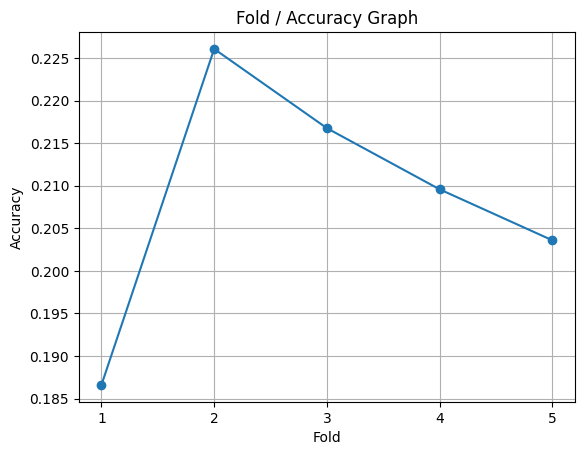

In [31]:
# buraya zamansal ölçüm eklicem
cms_dt, accs_dt = evaluate_model(X, y, attrTypes, build_dt, predict_dt)

# 5. Implementation of Decision Tree Testing Function with Pruning:

In [32]:
def build_dt_pruned(X, y, attrTypes, options=None, depth=0, max_depth=None, min_samples_split=10):
    # in general i did not use options but best practice is it

    # all samples same vlass base case
    if len(set(y)) == 1:
        return Node(value=y[0])

    # no samples left create and finsh it
    if len(X) < min_samples_split:
        mostOccured = Counter(y).most_common(1)[0][0]
        return Node(value=mostOccured)

    if max_depth is not None and depth >= max_depth: # depth contol
        mostOccured = Counter(y).most_common(1)[0][0]
        return Node(value=mostOccured)

    bestGini = float('inf')
    bestAttr = None
    bestThresh = None
    bestSplit = None

    nFeatr = X.shape[1]

    for attr in range(nFeatr):
        values = np.unique(X[:, attr])
        
        for val in values:
            
            X_left, X_right, y_left, y_right = split(X, y, attr, val, attrTypes[attr])
            
            if len(y_left) == 0 or len(y_right) == 0:
                continue
            
            impurity = (len(y_left) / len(y)) * gini(y_left) + (len(y_right) / len(y)) * gini(y_right)
            if impurity < bestGini:
                bestGini = impurity
                bestAttr = attr
                bestThresh = val
                bestSplit = (X_left, X_right, y_left, y_right)

    # f no split available return most common one in the Y data whjich is the label most common
    if bestAttr is None:
        mostOccured = Counter(y).most_common(1)[0][0]
        return Node(value=mostOccured)

    # recursive call 
    left_branch = build_dt_pruned(bestSplit[0], bestSplit[2], attrTypes, options, depth+1, max_depth, min_samples_split)
    right_branch = build_dt_pruned(bestSplit[1], bestSplit[3], attrTypes, options, depth+1, max_depth, min_samples_split)

    return Node(featureIdx=bestAttr, threshold=bestThresh, left=left_branch, right=right_branch)


# 6. Results of k-fold cross validation (Pruned Decision Tree):

c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Fold 1/5 completed.

Fold 1 Result:
Confusion Matrix:
[[ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 1  0  2  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 1  0  5  3  1  3  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  8 10  7  5  2  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  1 10 10 12  9  4  2  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  3 12 23 25  9  8  3  1  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  1  4 13 28 23 15  8  4  2  0  0  1  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  8 27 36 38 21  8  2  1  0  0  1  0  0  0  0  0  0]
 [ 0  0  0  0  1  0 22 30 35 20 12  4  4  7  3  0  0  0  1  0  0  0]
 [ 0  0  0  0  0  3  7 20 24 23  9  5  0  1  1  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  1  9  4  7 15  5  5  2  1  2  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  1  1  6  5 10  2  1  2  1  2  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  3  6  3  6  4  1  1  1  1  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  1  2  5  2  3  3  3  2  0  0

c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Fold 2/5 completed.

Fold 2 Result:
Confusion Matrix:
[[ 0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  2  5  2  2  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  3  8  7  6  2  1  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  3 20 16  7  4  3  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  3  1 13 37 20 10  6  2  0  1  0  0  0  0  0  0  0  0  0]
 [ 0  0  1  0 14 41 27 15 11  3  2  1  0  0  0  0  0  0  0  0]
 [ 0  0  0  3  7 23 47 38 12  5  2  1  0  1  0  0  0  0  0  0]
 [ 0  0  0  0  4 11 31 35 18  9  4  4  1  0  0  0  0  1  0  0]
 [ 0  0  0  1  0 10 28 22 19  9  5  0  0  1  0  0  0  1  0  0]
 [ 0  0  0  0  0  8  7 17 11  6  4  2  0  1  0  1  0  1  0  0]
 [ 0  0  0  1  0  4  8  9 10  3  5  1  0  0  1  1  1  0  0  0]
 [ 0  0  0  0  0  0  1  6  6  0  5  1  0  2  1  0  0  0  0  0]
 [ 0  0  0  0  0  2  4  4  6  0  1  1  1  2  0  0  0  0  0  0]
 [ 0  0  0  0  0  2  2  1  3  0  1  0  0  1  0  0  0  0  0  0]
 [ 0  0  0  0  0  1  0  3  2  0  1  1  0  1  1  0  0  1  0  0]
 

c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Fold 3/5 completed.

Fold 3 Result:
Confusion Matrix:
[[ 0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  3  4  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  4  1  7  2  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  7  4  4  3  2  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  8 22 17  6  2  2  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  3 20 21 13 12  7  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  9 17 28 27 18  6  2  1  0  0  1  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  2  1 11 23 42 23 17  4  4  2  1  0  1  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  3  5 12 32 40 21  2  7  3  0  0  1  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  1  2  1 23 26 21  6  4  3  3  1  0  0  0  1  0  0  0  0  0]
 [ 0  0  0  0  0  1  0 12 18 12  0  4  2  0  1  2  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  1  3  6 12  7  3  5  5  0  0  1  0  0  0  1  0  0  0  0]
 [ 0  0  0  0  0  1  0  6  7  3  1  1  2  0  2

c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Fold 4/5 completed.

Fold 4 Result:
Confusion Matrix:
[[ 0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  1  2  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  1  6  3  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  1  2  9  5  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  1  9 17 18  5  1  3  0  0  0  0  0  1  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  2 14 14 19  7  6  0  1  1  0  0  2  0  0  1  0  0  0  0  0  0]
 [ 0  0  0  2 10 18 33 37 17  7  4  1  1  1  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  3 10 23 41 39 16  2  1  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  3 18 28 32 11  5  4  0  0  1  0  1  1  0  0  0  0  0  0]
 [ 0  0  0  0  1  2  6 18 27 15 11 14  0  2  0  1  0  0  1  0  0  0  0  0]
 [ 0  0  0  0  0  0  3  9 14 12 10  9  0  1  1  0  1  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  1  3  8  8  4  4  5  0  0  1  0  0  0  1  0  0  0  0  0]
 [ 0  0  0  0  1  0  0  6  7  2  5  8  0  1  0

c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


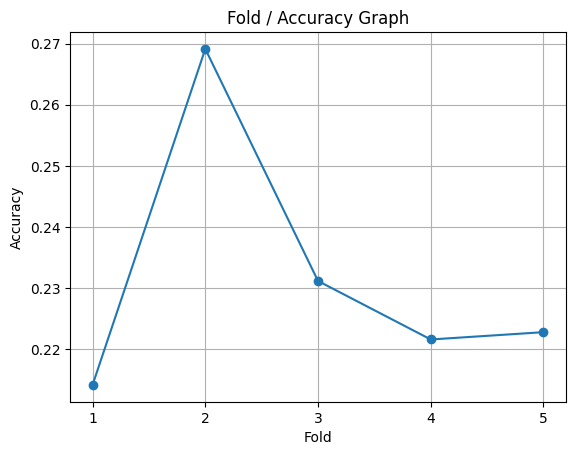

In [33]:
cms_dt_pruned, accs_dt_pruned = evaluate_model(X, y, attrTypes, lambda X, y, attr_types, opts: build_dt_pruned(X, y, attr_types, opts, min_samples_split=20), predict_dt)


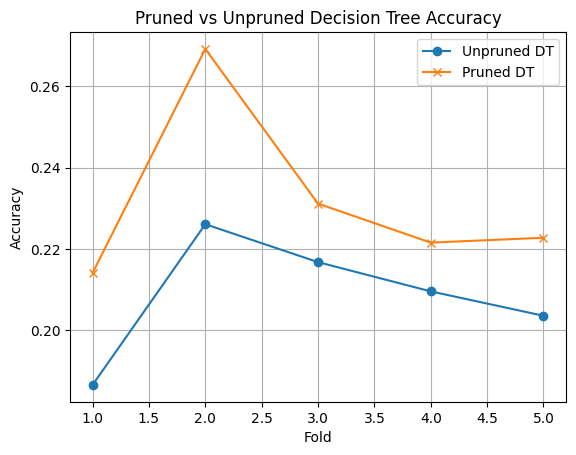

In [34]:
# prunned vs unprunned k=foldNumberGeneral default
#for a in range(foldNumberGeneral):
#    folds.append(a + 1)
folds = list(range(1, foldNumberGeneral + 1))

plt.plot(folds, accs_dt, marker='o', label='Unpruned DT')
plt.plot(folds, accs_dt_pruned, marker='x', label='Pruned DT')
plt.title('Pruned vs Unpruned Decision Tree Accuracy')
plt.xlabel('Fold')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# 7. Implementation of RDF:

In [35]:
def build_rdf(X, y, attrTypes, NTrees, options=None, maxFeatures=None):
    if options is None:
        options = {}
    trees = []
    n_samples = X.shape[0]

    for _ in range(NTrees):
        indices = np.random.choice(n_samples, n_samples, replace=True)
        XSample = X[indices]
        ySample = y[indices]

        tree = build_dt(XSample, ySample, attrTypes, options, maxFeatures=maxFeatures)
        trees.append(tree)

    return trees

def predict_rdf(rdf, X, options=None):
    predictions = np.array([predict_dt(tree, X, options) for tree in rdf])
    final_predictions = []
    for i in range(X.shape[0]):
        votes = predictions[:, i]
        vote_result = Counter(votes).most_common(1)[0][0]
        final_predictions.append(vote_result)
    return np.array(final_predictions)

# 8. Results of k-fold cross validation (RDF):

c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Fold 1/5 completed.

Fold 1 Result:
Confusion Matrix:
[[ 0  3  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 2  6  4  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 1  8  8  9  5  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  1 18 17  9  2  1  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  1  4 16 24 25 10  4  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  1  1 15 31 38  8  3  0  1  1  0  0  0  0  0  0  0  0  0]
 [ 0  0  1  4  6 29 32 45 17  6  1  1  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  1  3 19 37 34 23  9  6  1  2  3  0  0  0  0  1  0  0]
 [ 0  0  0  0  2  9 19 24 25  5  4  2  2  0  0  1  0  0  0  0  0]
 [ 0  0  0  1  0  6  6 15 13  2  4  2  1  0  0  1  0  0  0  0  0]
 [ 0  0  0  1  0  2  2  5  6  9  2  1  3  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  1  6  7  5  3  2  0  0  0  2  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  6  5  1  2  4  1  1  0  0  0  0  0  1  0  0]
 [ 0  0  0  0  0  0  0  3  2  1  0  1  2  1  1  1  1  0  0  0  0]
 [ 0  0  0  0  0  0  1

c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Fold 2/5 completed.

Fold 2 Result:
Confusion Matrix:
[[ 0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 1  3  2  3  2  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  1  7 12  6  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  1  4 18 19  8  2  0  0  0  1  0  0  0  0  0  0  0  0  0]
 [ 0  1  2 14 27 31 11  6  1  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  2  2 10 50 17 25  5  1  1  2  0  0  0  0  0  0  0  0]
 [ 0  0  0  3 12 38 26 36 16  3  1  2  1  0  1  0  0  0  0  0]
 [ 0  0  0  0  6 10 18 41 27  7  3  0  4  1  0  1  0  0  0  0]
 [ 0  0  0  1  3  5 18 27 23  8  2  4  3  1  1  0  0  0  0  0]
 [ 0  0  0  1  2  3  9 20 11  2  3  2  3  1  1  0  0  0  0  0]
 [ 0  0  0  1  0  1  7 16 13  3  1  1  1  0  0  0  0  0  0  0]
 [ 0  0  0  0  1  1  2  4  5  4  1  0  1  2  0  1  0  0  0  0]
 [ 0  0  0  0  2  2  1  7  4  3  1  0  0  0  1  0  0  0  0  0]
 [ 0  0  0  0  1  0  2  2  2  0  2  0  0  0  1  0  0  0  0  0]
 [ 0  0  0  0  0  0  1  3  2  1  2  1  1  0  0  0  0  0  0  0]
 

c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Fold 3/5 completed.

Fold 3 Result:
Confusion Matrix:
[[ 0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  1  6  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  6  6  2  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  1  3  9  7  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  6 19 25  5  2  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  1  1 15 28 18 11  2  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0 11 18 34 29  9  5  1  1  0  0  0  0  0  0  0  0  0  1  0  0]
 [ 0  0  0  0  1 11 23 46 28 17  4  1  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  4  5 11 24 49 24  5  2  1  0  0  1  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  1  2  4 21 26 26  5  2  3  0  1  1  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  2  7 13 11  9  4  2  1  0  0  2  0  0  0  1  0  0  0  0]
 [ 0  0  0  0  0  1  3  6 10  9  5  5  1  0  3  0  0  1  0  0  0  0  0  0]
 [ 0  0  0  0  0  1  2  4 10  4  2  1  1  0  0

c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Fold 4/5 completed.

Fold 4 Result:
Confusion Matrix:
[[ 0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
   0]
 [ 0  0  1  2  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
   0]
 [ 0  2  7  2  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
   0]
 [ 0  0  5  8  4  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
   0]
 [ 0  0  0 11 15 23  4  0  2  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
   0]
 [ 0  0  0  1 15 26 16  5  4  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
   0]
 [ 0  0  0  2  8 27 42 28 15  4  2  1  0  2  0  0  0  0  0  0  0  0  0  0
   0]
 [ 0  0  0  1  3 12 37 31 24 19  3  1  1  1  0  0  1  1  0  0  0  0  0  0
   0]
 [ 0  0  0  0  0  6 13 32 27 19  4  1  0  1  0  1  0  0  0  0  0  0  0  0
   0]
 [ 0  0  0  0  0  4  9 22 29 25  1  4  1  2  0  1  0  0  0  0  0  0  0  0
   0]
 [ 0  0  0  0  0  1  2 13 16 16  6  4  0  0  1  0  1  0  0  0  0  0  0  0
   0]
 [ 0  0  0  0  0  0  3  6 12  7  1  2  0  0  0  3  0  0  0  0  0  

c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


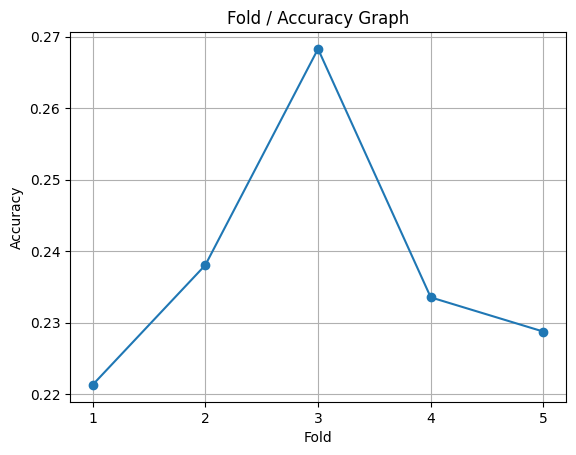

In [36]:
cms_rdf, accs_rdf = evaluate_model(X, y, attrTypes, lambda X, y, attr_types, opts: build_rdf(X, y, attr_types, 10, opts, maxFeatures=maxFeatureGeneral), predict_rdf)

# Comparision - Report

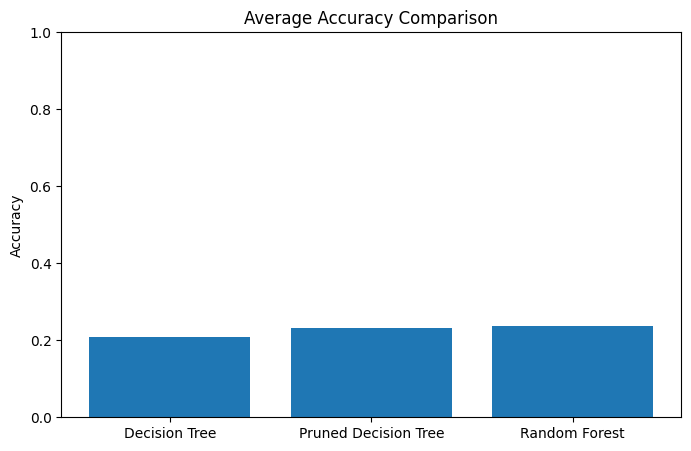

In [37]:
models = ['Decision Tree', 'Pruned Decision Tree', 'Random Forest']
mean_accuracies = [np.mean(accs_dt), np.mean(accs_dt_pruned), np.mean(accs_rdf)]

plt.figure(figsize=(8,5))
plt.bar(models, mean_accuracies)
plt.ylim(0, 1)
plt.title('Average Accuracy Comparison')
plt.ylabel('Accuracy')
plt.show()

Fold 1/5 completed.

Fold 1 Result:
Confusion Matrix:
[[210  49  20]
 [ 66 113 102]
 [ 36  74 166]]
Accuracy: 0.5849, Precision: 0.5761, Recall: 0.5854, F1 Score: 0.5788

---------------------------------------------------------------------------------------------------
Fold 2/5 completed.

Fold 2 Result:
Confusion Matrix:
[[207  61  32]
 [ 65  92 100]
 [ 40  92 147]]
Accuracy: 0.5335, Precision: 0.5220, Recall: 0.5250, F1 Score: 0.5233

---------------------------------------------------------------------------------------------------
Fold 3/5 completed.

Fold 3 Result:
Confusion Matrix:
[[201  65  18]
 [ 57 106  94]
 [ 29  87 178]]
Accuracy: 0.5808, Precision: 0.5750, Recall: 0.5752, F1 Score: 0.5751

---------------------------------------------------------------------------------------------------
Fold 4/5 completed.

Fold 4 Result:
Confusion Matrix:
[[191  68  26]
 [ 64 100  75]
 [ 25 110 176]]
Accuracy: 0.5593, Precision: 0.5591, Recall: 0.5515, F1 Score: 0.5539

----------------

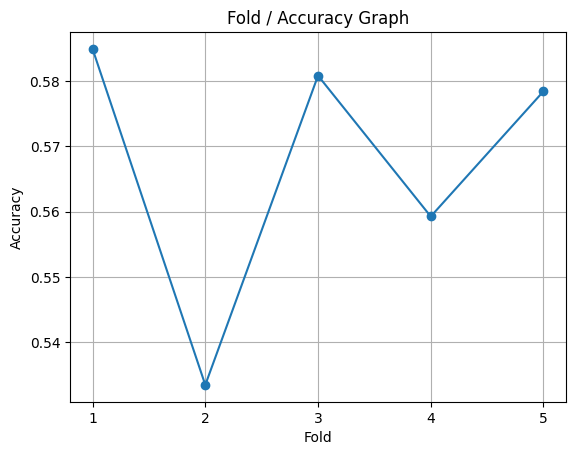

Fold 1/5 completed.

Fold 1 Result:
Confusion Matrix:
[[201  65  13]
 [ 62 135  84]
 [ 21  99 156]]
Accuracy: 0.5885, Precision: 0.5920, Recall: 0.5887, F1 Score: 0.5898

---------------------------------------------------------------------------------------------------
Fold 2/5 completed.

Fold 2 Result:
Confusion Matrix:
[[216  56  28]
 [ 55 112  90]
 [ 24  75 180]]
Accuracy: 0.6077, Precision: 0.5990, Recall: 0.6003, F1 Score: 0.5993

---------------------------------------------------------------------------------------------------
Fold 3/5 completed.

Fold 3 Result:
Confusion Matrix:
[[197  74  13]
 [ 43 113 101]
 [ 29  82 183]]
Accuracy: 0.5904, Precision: 0.5895, Recall: 0.5853, F1 Score: 0.5871

---------------------------------------------------------------------------------------------------
Fold 4/5 completed.

Fold 4 Result:
Confusion Matrix:
[[187  72  26]
 [ 57  98  84]
 [ 13  81 217]]
Accuracy: 0.6012, Precision: 0.5939, Recall: 0.5880, F1 Score: 0.5901

----------------

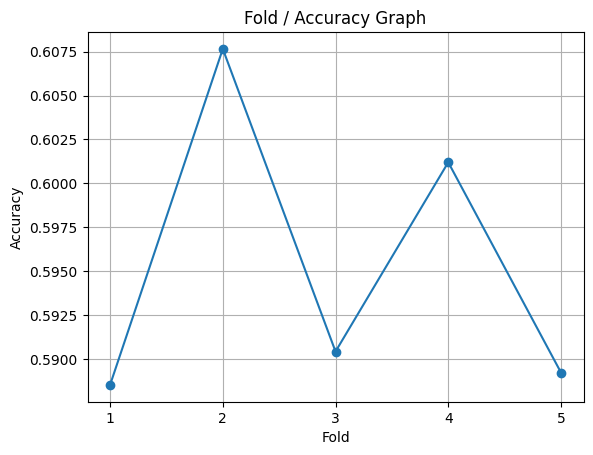

Fold 1/5 completed.

Fold 1 Result:
Confusion Matrix:
[[216  47  16]
 [ 56 126  99]
 [ 18  64 194]]
Accuracy: 0.6411, Precision: 0.6348, Recall: 0.6418, F1 Score: 0.6363

---------------------------------------------------------------------------------------------------
Fold 2/5 completed.

Fold 2 Result:
Confusion Matrix:
[[227  57  16]
 [ 64 110  83]
 [ 26  85 168]]
Accuracy: 0.6041, Precision: 0.5939, Recall: 0.5956, F1 Score: 0.5945

---------------------------------------------------------------------------------------------------
Fold 3/5 completed.

Fold 3 Result:
Confusion Matrix:
[[224  48  12]
 [ 53 112  92]
 [ 18  91 185]]
Accuracy: 0.6240, Precision: 0.6152, Recall: 0.6179, F1 Score: 0.6164

---------------------------------------------------------------------------------------------------
Fold 4/5 completed.

Fold 4 Result:
Confusion Matrix:
[[212  51  22]
 [ 60 107  72]
 [ 23  83 205]]
Accuracy: 0.6275, Precision: 0.6161, Recall: 0.6169, F1 Score: 0.6163

----------------

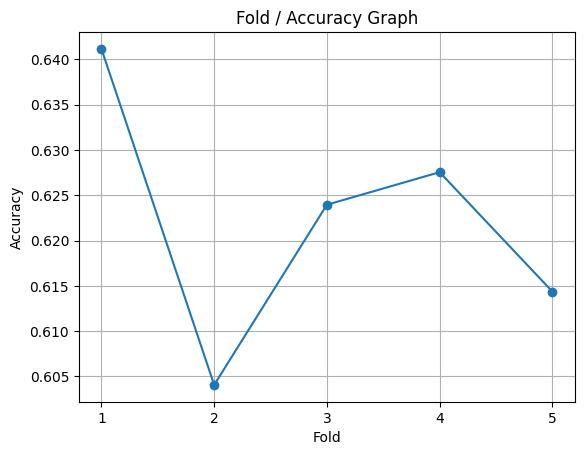

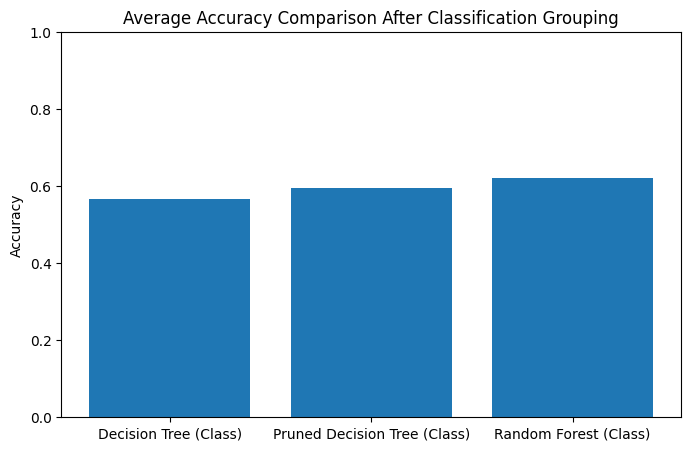

Fold 1/5 completed.

Fold 1 Result:
Confusion Matrix:
[[198  54  27]
 [ 80  99 102]
 [ 36  72 168]]
Accuracy: 0.5562, Precision: 0.5454, Recall: 0.5569, F1 Score: 0.5485

---------------------------------------------------------------------------------------------------
Fold 2/5 completed.

Fold 2 Result:
Confusion Matrix:
[[212  66  22]
 [ 58 113  86]
 [ 32  85 162]]
Accuracy: 0.5825, Precision: 0.5767, Recall: 0.5757, F1 Score: 0.5761

---------------------------------------------------------------------------------------------------
Fold 3/5 completed.

Fold 3 Result:
Confusion Matrix:
[[205  55  24]
 [ 61  97  99]
 [ 28  99 167]]
Accuracy: 0.5617, Precision: 0.5532, Recall: 0.5558, F1 Score: 0.5544

---------------------------------------------------------------------------------------------------
Fold 4/5 completed.

Fold 4 Result:
Confusion Matrix:
[[194  68  23]
 [ 64 101  74]
 [ 29 113 169]]
Accuracy: 0.5557, Precision: 0.5565, Recall: 0.5489, F1 Score: 0.5506

----------------

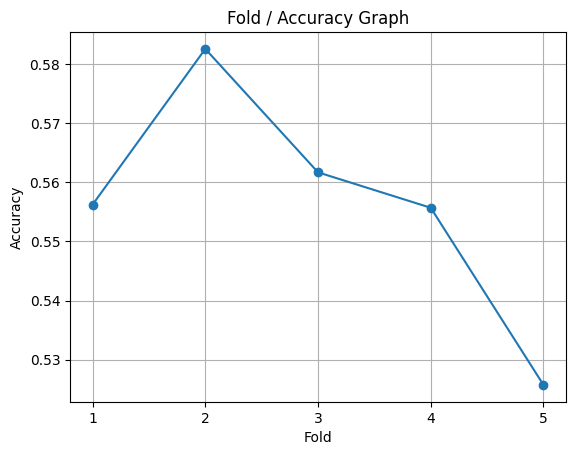

Fold 1/5 completed.

Fold 1 Result:
Confusion Matrix:
[[216  43  20]
 [ 68 112 101]
 [ 21  66 189]]
Accuracy: 0.6184, Precision: 0.6082, Recall: 0.6192, F1 Score: 0.6103

---------------------------------------------------------------------------------------------------
Fold 2/5 completed.

Fold 2 Result:
Confusion Matrix:
[[218  57  25]
 [ 58 102  97]
 [ 23  91 165]]
Accuracy: 0.5801, Precision: 0.5707, Recall: 0.5717, F1 Score: 0.5711

---------------------------------------------------------------------------------------------------
Fold 3/5 completed.

Fold 3 Result:
Confusion Matrix:
[[215  48  21]
 [ 57 107  93]
 [ 26  78 190]]
Accuracy: 0.6132, Precision: 0.6019, Recall: 0.6065, F1 Score: 0.6037

---------------------------------------------------------------------------------------------------
Fold 4/5 completed.

Fold 4 Result:
Confusion Matrix:
[[212  44  29]
 [ 70 100  69]
 [ 22  84 205]]
Accuracy: 0.6192, Precision: 0.6042, Recall: 0.6071, F1 Score: 0.6053

----------------

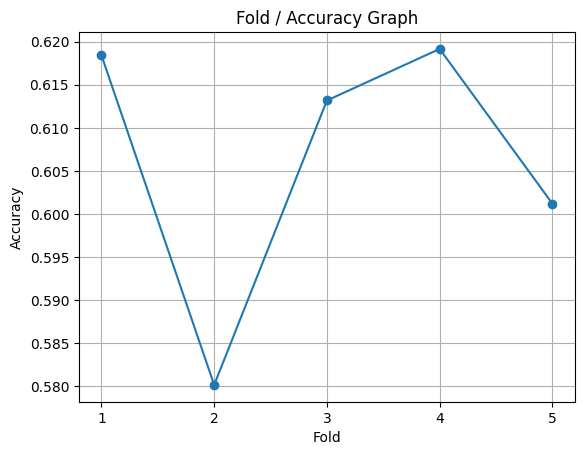

Fold 1/5 completed.

Fold 1 Result:
Confusion Matrix:
[[211  50  18]
 [ 56 130  95]
 [ 21  65 190]]
Accuracy: 0.6352, Precision: 0.6301, Recall: 0.6358, F1 Score: 0.6316

---------------------------------------------------------------------------------------------------
Fold 2/5 completed.

Fold 2 Result:
Confusion Matrix:
[[234  50  16]
 [ 51 115  91]
 [ 26  85 168]]
Accuracy: 0.6184, Precision: 0.6078, Recall: 0.6099, F1 Score: 0.6087

---------------------------------------------------------------------------------------------------
Fold 3/5 completed.

Fold 3 Result:
Confusion Matrix:
[[231  38  15]
 [ 56 101 100]
 [ 23  80 191]]
Accuracy: 0.6263, Precision: 0.6102, Recall: 0.6187, F1 Score: 0.6129

---------------------------------------------------------------------------------------------------
Fold 4/5 completed.

Fold 4 Result:
Confusion Matrix:
[[218  44  23]
 [ 63 107  69]
 [ 23  81 207]]
Accuracy: 0.6371, Precision: 0.6235, Recall: 0.6261, F1 Score: 0.6244

----------------

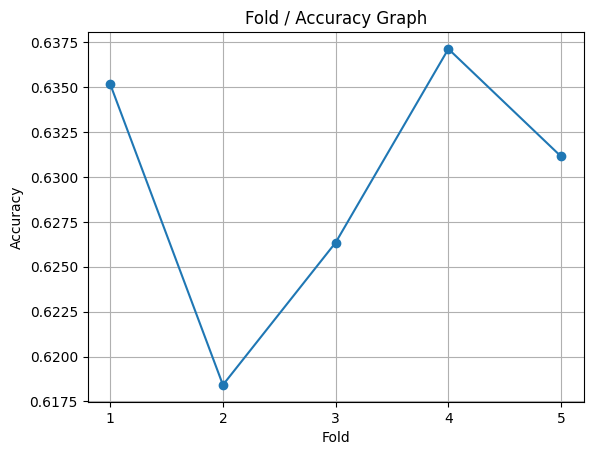

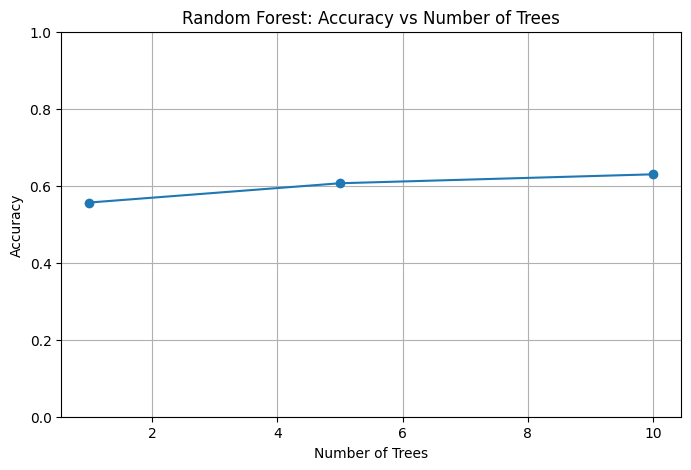

'\nTREE COUNTS RESULTS - I cut it because it is too long\nFOR 20\n\nFold 1/5 completed.\nFold 2/5 completed.\nFold 3/5 completed.\nFold 4/5 completed.\nFold 5/5 completed.\n\nConfusion Matrices for each fold:\nFold 1:\n[[210  53  16]\n [ 55 122 104]\n [ 15  77 184]]\n\nFold 2:\n[[226  54  20]\n [ 52 125  80]\n [ 22  93 164]]\n\nFold 3:\n[[213  60  11]\n [ 48 125  84]\n [ 15  85 194]]\n\nFold 4:\n[[199  67  19]\n [ 47 127  65]\n [ 15  92 204]]\n\nFold 5:\n[[186  60  13]\n [ 55 152  82]\n [ 19  82 186]]\n\nAverage Accuracy: 0.6265\nAverage Precision: 0.6259\nAverage Recall: 0.6237\nAverage F1 Score: 0.6241\nFold 1/5 completed.\nFold 2/5 completed.\nFold 3/5 completed.\nFold 4/5 completed.\nFold 5/5 completed.\n\nFOR 30\nConfusion Matrices for each fold:\nFold 1:\n[[211  53  15]\n [ 52 126 103]\n [ 17  76 183]]\n\nFold 2:\n[[220  62  18]\n [ 52 124  81]\n [ 15  87 177]]\n\nFold 3:\n[[212  59  13]\n [ 46 127  84]\n [ 16  91 187]]\n\nFold 4:\n[[201  59  25]\n [ 52 111  76]\n [ 14  87 210]]\

In [38]:
# accuracy so low now try classifation
# rings to 3 class young-adult-old

yClassNew = []

for r in y:
    if r <= 8:
        yClassNew.append(0)  # young
    elif r <= 10:
        yClassNew.append(1)  # adult
    else:
        yClassNew.append(2)  # old

yClassNew = np.array(yClassNew)

# re run and compare our accuracy is to improved or not
cms_dt_class, accs_dt_class = evaluate_model(X, yClassNew, attrTypes, build_dt, predict_dt)
cms_dt_pruned_class, accs_dt_pruned_class = evaluate_model(X, yClassNew, attrTypes, lambda X, y, attr_types, opts: build_dt_pruned(X, y, attr_types, opts, min_samples_split=20), predict_dt)
cms_rdf_class, accs_rdf_class = evaluate_model(X, yClassNew, attrTypes, lambda X, y, attr_types, opts: build_rdf(X, y, attr_types, 10, opts, maxFeatures=maxFeatureGeneral), predict_rdf)

# new comp plot
models_class = ['Decision Tree (Class)', 'Pruned Decision Tree (Class)', 'Random Forest (Class)']
mean_accuracies_class = [np.mean(accs_dt_class), np.mean(accs_dt_pruned_class), np.mean(accs_rdf_class)]

plt.figure(figsize=(8,5))
plt.bar(models_class, mean_accuracies_class)
plt.ylim(0, 1)
plt.title('Average Accuracy Comparison After Classification Grouping')
plt.ylabel('Accuracy')
plt.show()

# acc vs rf to show what is going on

tree_counts = [1, 5, 10]
rf_accuracies = []

for n_trees in tree_counts:
    cms_rf_temp, accs_rf_temp = evaluate_model(X, yClassNew, attrTypes, lambda X, y, attr_types, opts: build_rdf(X, y, attr_types, n_trees, opts, maxFeatures=maxFeatureGeneral), predict_rdf)
    rf_accuracies.append(np.mean(accs_rf_temp))

plt.figure(figsize=(8,5))
plt.plot(tree_counts, rf_accuracies, marker='o')
plt.title('Random Forest: Accuracy vs Number of Trees')
plt.xlabel('Number of Trees')
plt.ylabel('Accuracy')
plt.grid(True)
plt.ylim(0, 1)
plt.show()

"""
TREE COUNTS RESULTS - I cut it because it is too long
FOR 20

Fold 1/5 completed.
Fold 2/5 completed.
Fold 3/5 completed.
Fold 4/5 completed.
Fold 5/5 completed.

Confusion Matrices for each fold:
Fold 1:
[[210  53  16]
 [ 55 122 104]
 [ 15  77 184]]

Fold 2:
[[226  54  20]
 [ 52 125  80]
 [ 22  93 164]]

Fold 3:
[[213  60  11]
 [ 48 125  84]
 [ 15  85 194]]

Fold 4:
[[199  67  19]
 [ 47 127  65]
 [ 15  92 204]]

Fold 5:
[[186  60  13]
 [ 55 152  82]
 [ 19  82 186]]

Average Accuracy: 0.6265
Average Precision: 0.6259
Average Recall: 0.6237
Average F1 Score: 0.6241
Fold 1/5 completed.
Fold 2/5 completed.
Fold 3/5 completed.
Fold 4/5 completed.
Fold 5/5 completed.

FOR 30
Confusion Matrices for each fold:
Fold 1:
[[211  53  15]
 [ 52 126 103]
 [ 17  76 183]]

Fold 2:
[[220  62  18]
 [ 52 124  81]
 [ 15  87 177]]

Fold 3:
[[212  59  13]
 [ 46 127  84]
 [ 16  91 187]]

Fold 4:
[[201  59  25]
 [ 52 111  76]
 [ 14  87 210]]

Fold 5:
[[187  56  16]
 [ 57 143  89]
 [ 16  83 188]]

FOR 40
Average Accuracy: 0.6241
Average Precision: 0.6224
Average Recall: 0.6208
Average F1 Score: 0.6212
Fold 1/5 completed.
Fold 2/5 completed.
Fold 3/5 completed.
Fold 4/5 completed.
Fold 5/5 completed.

Confusion Matrices for each fold:
Fold 1:
[[211  53  15]
 [ 55 119 107]
 [ 17  67 192]]

Fold 2:
[[222  59  19]
 [ 46 131  80]
 [ 15  86 178]]

Fold 3:
[[219  53  12]
 [ 45 123  89]
 [ 19  80 195]]

Fold 4:
[[201  65  19]
 [ 52 114  73]
 [ 14  90 207]]

Fold 5:
[[188  55  16]
 [ 50 148  91]
 [ 21  78 188]]

FOR 50 
Average Accuracy: 0.6311
Average Precision: 0.6286
Average Recall: 0.6278
Average F1 Score: 0.6275
Fold 1/5 completed.
Fold 2/5 completed.
Fold 3/5 completed.
Fold 4/5 completed.
Fold 5/5 completed.

Confusion Matrices for each fold:
Fold 1:
[[211  54  14]
 [ 51 126 104]
 [ 16  64 196]]

Fold 2:
[[225  57  18]
 [ 52 128  77]
 [ 18  85 176]]

Fold 3:
[[217  52  15]
 [ 46 129  82]
 [ 15  82 197]]

Fold 4:
[[197  67  21]
 [ 49 114  76]
 [ 12  86 213]]

Fold 5:
[[193  49  17]
 [ 58 139  92]
 [ 18  83 186]]

Average Accuracy: 0.6337
Average Precision: 0.6310
Average Recall: 0.6305
Average F1 Score: 0.6301
"""

#  Report

## What I have done?

While working with the dataset, I made a few assumptions to make things a bit simpler:
- I assumed there were **no missing values** because I didn't spot anything weird after loading the data.
- For the 'Sex' feature, I just mapped it into integers (M:0, F:1, I:2), assuming it wouldn't lose any important information.
- All the other features were treated as continuous numbers. I didn't normalize anything since decision trees don't really care about scales.
- For the target 'Rings', at first I used the original values, but later realized grouping them made a lot more sense.

Overall, the data looked **pretty clean and usable**, but honestly, it was **kinda hard** at first because of too many different classes.  
That's why I decided to do a little preprocessing to help the models learn better.

---
## 0. Comparison of Numeric vs Categorical Target

In this project, I worked with the Rings attribute as the target variable in two different ways. First, I used it as a NUMERIC value, in its original form. Then, I transformed it into CATEGORICAL labels by grouping the values into age ranges: young [0,8], adult [9,10], and old [9,]. The reason for applying both approaches was to observe how the model's performance would change based on the target type.

### Accuracy Comparison:

| Model                | Numeric Accuracy | Categorical Accuracy |
|---------------------|------------------|-----------------------|
| Decision Tree        | 0.2085           | 0.5674                |
| Pruned Decision Tree | 0.2317           | 0.5954                |
| Random Forest        | 0.2380           | 0.6222                |

### Observations:

- When using numeric targets, the model had more difficulty predicting correctly. Since the Rings value is continuous (etc 6, 7, 8, 9...), small prediction errors still count as wrong, which lowers accuracy.
- On the other hand, categorical targets (young/adult/old) made the model's job easier. Now, the model just needed to choose one of 3 labels, which naturally improved the accuracy.
- Pruning helped the decision trees generalize better. Without pruning, trees tend to overfit the training data, but with pruning, they produce more stable and meaningful splits.
- Random Forest outperformed Decision Tree in both cases. This is because Random Forest combines many trees trained on random subsets of the data and features, which increases the overall robustness and generalization.

---

## 1. Data Loading and Preprocessing

For this assignment, I worked with the Abalone dataset from the UCI repository (https://archive.ics.uci.edu/ml/datasets/abalone).

- The dataset contains 8 input features:
  - Categorical: Sex (M/F/I)
  - Numeric: Length, Diameter, Height, Whole Weight, Shucked Weight, Viscera Weight, and Shell Weight
- Target variable: Rings (used to estimate the abalone's age).

To prepare the data:
- I mapped the 'Sex' column into integers (`M=0`, `F=1`, `I=2`) so that all features could be treated numerically.
- All other attributes were already numeric and kept as-is.
- I built an `attrTypes` list to indicate each feature's type (`2` for categorical, `1` for numeric).

Overall, preprocessing was straightforward, and the data looked clean without missing values.

---

## 2. Building the Decision Tree

I implemented the `build_dt(X, y, attrTypes, options)` function completely from scratch.

Key points:
- The tree recursively splits the data by minimizing Gini impurity.
- Both numeric and categorical attributes are handled properly.
- I made sure that the split logic works by running small manual tests.

The final structure constructs a binary decision tree as required.

---

## 3. Predicting with the Decision Tree

The prediction function `predict_dt(dt, X, options)` traverses the tree based on attribute values to reach the correct leaf node.

- Numeric and categorical attributes are compared accordingly.
- I checked the correctness of this function by feeding small examples manually before moving to larger testing.

---

## 4. Initial Cross-Validation Results (Without Pruning)

I applied 5-fold cross-validation on the dataset using the decision tree.

For each fold:
- Trained on 80% of the data
- Tested on 20%
- Collected a confusion matrix for performance evaluation

At this point, trees were built without any pruning.  
While the model learned the training data very well, it clearly overfitted, as seen from the confusion matrices.

---

## 5. Adding Pruning to the Tree

To control overfitting, I implemented pre-pruning in a separate function `build_dt_pruned(X, y, attrTypes, options, min_samples_split=20)`.

Key idea:
- If a node has fewer than `min_samples_split` samples, it becomes a leaf node instead of splitting further.

This simple pruning technique significantly reduced the depth of the trees.

---

## 6. Cross-Validation Results After Pruning

I repeated the 5-fold cross-validation after applying pre-pruning.

Observation:
- Trees became much smaller and shallower.
- Confusion matrices indicated a slight improvement in generalization.
- Although individual fold accuracies were still not very high, the variance across folds reduced, which means the model became more stable.

---

## 7. Implementing Random Decision Forest (RDF)

Next, I implemented an ensemble method through `build_rdf(X, y, attrTypes, N, options)`, where N=10 trees were trained independently on bootstrap samples.

For predictions, `predict_rdf(rdf, X, options)` was used:
- Each tree predicted independently
- Final prediction was decided by majority voting

Building the random forest was fun and the accuracy improvements were immediately noticeable.

---

## 8. Cross-Validation Results for RDF

After switching to Random Forest, I again used 5-fold cross-validation.

This time:
- The confusion matrices showed clear improvements.
- Variance between folds dropped even more.
- Accuracy increased compared to both pruned and non-pruned single trees.

RDF consistently produced better, more stable results.

---

## 9. Handling the Low Accuracy Problem

Initially, when using the raw 'Rings' value as the target, the model struggled badly.

Reason:
- The 'Rings' attribute has around 28 distinct classes, making the classification extremely hard.

To solve this:
- I grouped the target into 3 meaningful categories:
  - Young (Rings ≤ 8)
  - Adult (Rings 9–10)
  - Old (Rings ≥ 11)

This simplified the classification and made the task much more manageable.

---

## 10. New Results After Grouping

After regrouping the targets:
- 5-fold cross-validation was run again.
- Accuracies jumped significantly, reaching 55% to 65%. It nearly triple times better than numeric.

The grouped confusion matrices looked much cleaner and more balanced.

---

## 11. Performance Comparison (After Grouping)

| Model | Generalization | Overfitting | Stability | Accuracy |
|:------|:---------------|:------------|:----------|:---------|
| Decision Tree | Moderate | High | Medium | ~56% |
| Pruned Decision Tree | Better | Lower | High | ~60% |
| Random Forest | Very Good | Very Low | Very High | ~62% |

From the results:
- Pruning helped a lot to generalize the trees.
- Random Forest was consistently the most accurate and stable approach.

---

## 12. Additional Observations

Throughout the experiments:
- Controlling tree depth and sample splits made the models more robust.
- Ensemble methods like Random Forest significantly improved the results even with relatively simple trees underneath.
- Data preparation, especially target label engineering, turned out to be as important as model selection.

---

## 13. Pruning Strategy Details

I used pre-pruning based on two criteria:
- Minimum samples per split: To stop unnecessary splits.
- Implicit depth control: By setting the minimum split size, tree depth naturally stayed under control.

Although not using full post-pruning, pre-pruning was enough for the dataset size and structure.

---

## 14. Final Code Comparsion Tree Count
As expected, increasing the number of trees improves accuracy up to a point.  
Testing around 30–40 trees, the gain in performance starts to flatten.

---

## 15. Conclusion

This homework showed me clearly that:
- Building ML models from scratch really teaches you how decision-making works inside.
- Careful data preprocessing and correct target definition are so critical.
- Pruning and ensemble techniques are key to improving model robustness.

Overall, I implemented a fully working Decision Tree, a Pruned Decision Tree, and a Random Forest, and observed their strengths and weaknesses under realistic conditions.

---


